In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from matplotlib.colors import LinearSegmentedColormap

from f1_stats import (load_gaps, pair_season_table, pair_gap, estimate_tau2, chain, find_file,
                      fit_ratings, predicted_gap, session_gap_to_fastest, iqr_mean,
                      setup_plot_style, short, PAIR_SEASON, REFERENCE, TEAM_LINEAGE,
                      BLUE, MUTED, INK, BLUE_RAMP)

setup_plot_style()
os.makedirs('data', exist_ok=True)
os.makedirs('figures', exist_ok=True)

gaps = load_gaps()
ps = pair_season_table(gaps)
usable = ps[ps['usable']]
tau2, _ = estimate_tau2(ps)
print(f'{len(usable)} usable pair-seasons, tau^2 = {tau2:.4f}')

137 usable pair-seasons, tau^2 = 0.0153


In [2]:
def network(years):
    g = nx.Graph()
    sub = usable[usable['year'].isin(list(years))]
    g.add_edges_from(zip(sub['A'], sub['B']))
    return g

full = network(range(2014, 2027))
groups = sorted(nx.connected_components(full), key=len, reverse=True)
print(f'All seasons: {full.number_of_nodes()} drivers in {len(groups)} groups, sizes {[len(c) for c in groups]}')
for c in groups[1:]:
    print('   never linked to the rest:', ', '.join(short(d) for d in sorted(c)))
for window in [(2025, 2026), (2024, 2025)]:
    g = network(range(window[0], window[1] + 1))
    size = len(nx.node_connected_component(g, REFERENCE)) if REFERENCE in g else 0
    print(f'Using only {window[0]}-{window[1]}: Russell is linked to {size} drivers (including himself)')
print('Shortest chain Russell -> Verstappen (all seasons):',
      ' -> '.join(short(d) for d in nx.shortest_path(full, REFERENCE, 'max-verstappen')))

All seasons: 57 drivers in 3 groups, sizes [53, 2, 2]
   never linked to the rest: Bianchi, Chilton
   never linked to the rest: Merhi, Stevens
Using only 2025-2026: Russell is linked to 2 drivers (including himself)
Using only 2024-2025: Russell is linked to 11 drivers (including himself)
Shortest chain Russell -> Verstappen (all seasons): Russell -> Latifi -> Albon -> Verstappen


In [3]:
rows = []
for year in range(2014, 2027):
    fit = fit_ratings(ps, year, tau2)                  # Russell = 0
    raced = set(gaps.loc[gaps['year'] == year, 'A']) | set(gaps.loc[gaps['year'] == year, 'B'])
    for d in sorted(raced & set(fit['theta'].index)):
        se = float(np.sqrt(fit['cov'].loc[d, d]))
        rows.append({'year': year, 'driver': d, 'rating': fit['theta'][d], 'se': se,
                     'ci_low': fit['theta'][d] - 1.96 * se, 'ci_high': fit['theta'][d] + 1.96 * se})
ratings = pd.DataFrame(rows)
print(f'{len(ratings)} driver-season ratings')
ratings[ratings['year'] == 2025].sort_values('rating').round(3)

279 driver-season ratings


,year,driver,rating,se,ci_low,ci_high
250,2025,max-verstappen,-0.417,0.162,-0.733,-0.100
244,2025,isack-hadjar,-0.272,0.215,-0.693,0.150
247,2025,lando-norris,-0.162,0.197,-0.547,0.224
238,2025,charles-leclerc,-0.114,0.107,-0.323,0.095
249,2025,liam-lawson,-0.105,0.225,-0.546,0.336
253,2025,oscar-piastri,-0.098,0.201,-0.492,0.296
237,2025,carlos-sainz-jr,-0.080,0.130,-0.336,0.176
242,2025,gabriel-bortoleto,-0.052,0.220,-0.483,0.379
252,2025,oliver-bearman,-0.050,0.188,-0.418,0.319
243,2025,george-russell,0.000,0.000,0.000,0.000


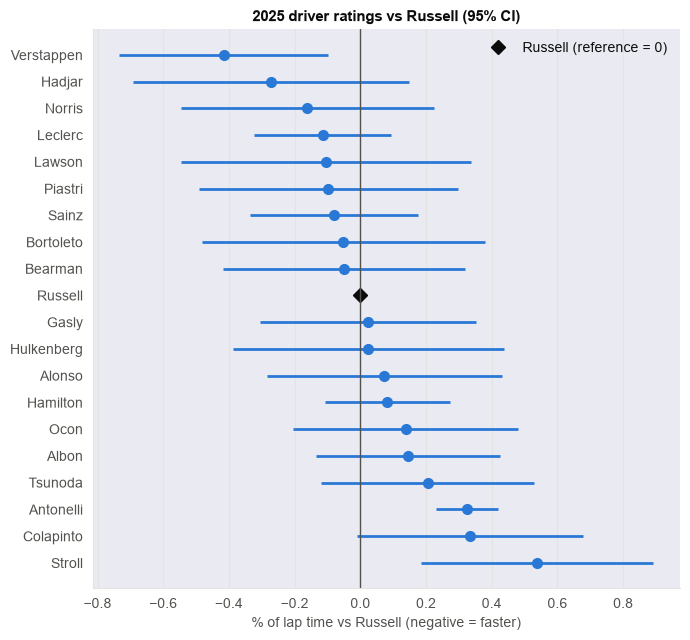

In [4]:
d = ratings[ratings['year'] == 2025].sort_values('rating', ascending=False).reset_index(drop=True)
y = np.arange(len(d))
is_ref = (d['driver'] == REFERENCE).to_numpy()

fig, ax = plt.subplots(figsize=(7, 6.5))
ax.hlines(y, d['ci_low'], d['ci_high'], color=BLUE, linewidth=2)
ax.plot(d.loc[~is_ref, 'rating'], y[~is_ref], 'o', color=BLUE, markersize=7)
ax.plot(d.loc[is_ref, 'rating'], y[is_ref], 'D', color=INK, markersize=7, label='Russell (reference = 0)')
ax.axvline(0, color=MUTED, linewidth=1)
ax.set_yticks(y, [short(x) for x in d['driver']])
ax.grid(axis='y', visible=False)
ax.set_title('2025 driver ratings vs Russell (95% CI)')
ax.set_xlabel('% of lap time vs Russell (negative = faster)')
ax.legend(loc='upper right')
fig.tight_layout()
fig.savefig('figures/driver_ratings_2025.png', bbox_inches='tight')
plt.show()

In [5]:
link1 = pair_gap(usable, 2025, 'kimi-antonelli', 'george-russell')
link2 = pair_gap(usable, 2024, 'george-russell', 'lewis-hamilton')
g_chain, _, se_chain = chain([(link1['mean'], link1['se']), (link2['mean'], link2['se'])], 1, tau2)
g_fit, se_fit = predicted_gap(fit_ratings(ps, 2025, tau2), 'kimi-antonelli', 'lewis-hamilton')

print(f'Short chain via Russell (Eq. 4): {g_chain:+.2f}%  (95% CI {g_chain - 1.96*se_chain:+.2f} to {g_chain + 1.96*se_chain:+.2f})')
print(f'Full weighted fit:               {g_fit:+.2f}%  (95% CI {g_fit - 1.96*se_fit:+.2f} to {g_fit + 1.96*se_fit:+.2f})')
print('Both say Antonelli was slightly slower; the full fit is tighter because it combines several paths.')

Short chain via Russell (Eq. 4): +0.16%  (95% CI -0.12 to +0.45)
Full weighted fit:               +0.24%  (95% CI +0.03 to +0.46)
Both say Antonelli was slightly slower; the full fit is tighter because it combines several paths.


In [6]:
rows = []
for r in usable.itertuples():
    fit = fit_ratings(ps, r.year, tau2, drop_pair=(r.A, r.B), reference=r.A)
    pred, se_pred = predicted_gap(fit, r.A, r.B)
    rows.append({'year': r.year, 'team': r.team, 'A': r.A, 'B': r.B, 'actual': r.mean,
                 'se_actual': r.se, 'predicted': pred, 'se_predicted': se_pred})
backtest = pd.DataFrame(rows)
linked = backtest.dropna(subset=['predicted']).copy()
total_se = np.sqrt(linked['se_predicted']**2 + linked['se_actual']**2)
linked['inside_95'] = (linked['actual'] - linked['predicted']).abs() <= 1.96 * total_se
err = linked['actual'] - linked['predicted']

print(f'{len(linked)} of {len(backtest)} hidden pairs could still be linked through other drivers')
print(f"Coverage (real gap inside the 95% interval): {linked['inside_95'].mean():.0%}   (target ~95%)")
print(f"Picks the faster driver: {(np.sign(linked['actual']) == np.sign(linked['predicted'])).mean():.0%}   (coin flip = 50%)")
print(f"MAE of the chained prediction: {err.abs().mean():.2f}   (guessing 0 instead: {linked['actual'].abs().mean():.2f})")

90 of 137 hidden pairs could still be linked through other drivers
Coverage (real gap inside the 95% interval): 82%   (target ~95%)
Picks the faster driver: 71%   (coin flip = 50%)
MAE of the chained prediction: 0.30   (guessing 0 instead: 0.27)


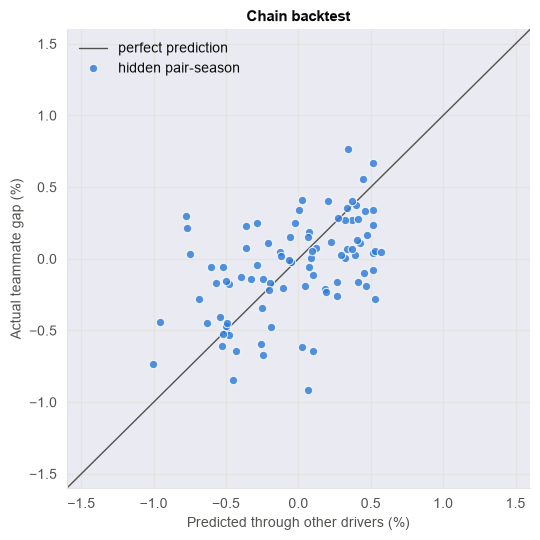

In [7]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
lim = 1.6
ax.plot([-lim, lim], [-lim, lim], color=MUTED, linewidth=1, label='perfect prediction')
ax.plot(linked['predicted'], linked['actual'], 'o', color=BLUE, markersize=6, alpha=0.8,
        markeredgecolor='white', markeredgewidth=0.8, label='hidden pair-season')
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
ax.set_xlabel('Predicted through other drivers (%)')
ax.set_ylabel('Actual teammate gap (%)')
ax.set_title('Chain backtest')
ax.legend(loc='upper left')
fig.tight_layout()
fig.savefig('figures/chain_backtest.png', bbox_inches='tight')
plt.show()

In [8]:
quali = pd.read_csv(find_file('qualifying_clean.csv'))
gp = session_gap_to_fastest(gaps, quali)
P = gp.groupby(PAIR_SEASON)['P_team'].apply(iqr_mean).unstack().reset_index()
P = P.merge(usable[PAIR_SEASON + ['sessions']], on=PAIR_SEASON)   # usable pair-seasons only

fits = {year: fit_ratings(ps, year, tau2) for year in sorted(P['year'].unique())}
rows = []
for r in P.itertuples():
    th, cov = fits[r.year]['theta'], fits[r.year]['cov']
    if r.A in th.index and r.B in th.index:
        avg_rating = (th[r.A] + th[r.B]) / 2
        var_rating = (cov.loc[r.A, r.A] + cov.loc[r.B, r.B] + 2 * cov.loc[r.A, r.B]) / 4
        rows.append({'year': r.year, 'team': r.team, 'A': r.A, 'B': r.B, 'sessions': r.sessions,
                     'gap_to_fastest': r.mean, 'avg_rating': avg_rating,
                     'car_pace': r.mean - avg_rating, 'car_pace_se': np.sqrt(r.se**2 + var_rating)})
car_pairs = pd.DataFrame(rows)
print(f'Car pace estimated for {len(car_pairs)} of {len(P)} usable pair-seasons')

def combine(d):
    w = d['sessions']
    return pd.Series({'car_pace': np.average(d['car_pace'], weights=w),
                      'se': np.sqrt((w**2 * d['car_pace_se']**2).sum()) / w.sum(),
                      'pairs': len(d)})

car = car_pairs.groupby(['year', 'team']).apply(combine, include_groups=False).reset_index()
car['ci_low'] = car['car_pace'] - 1.96 * car['se']
car['ci_high'] = car['car_pace'] + 1.96 * car['se']
car[car['year'] == 2025].sort_values('car_pace').round(2)

Car pace estimated for 135 of 137 usable pair-seasons


,year,team,car_pace,se,pairs,ci_low,ci_high
116,2025,mercedes,0.31,0.05,1.0,0.21,0.41
115,2025,mclaren,0.32,0.20,1.0,-0.07,0.72
111,2025,aston-martin,0.67,0.19,1.0,0.30,1.04
112,2025,ferrari,0.68,0.11,1.0,0.47,0.90
118,2025,red-bull,0.75,0.17,1.0,0.41,1.08
119,2025,williams,0.82,0.14,1.0,0.55,1.09
113,2025,haas,0.89,0.18,1.0,0.53,1.25
114,2025,kick-sauber,0.95,0.22,1.0,0.52,1.38
110,2025,alpine,0.95,0.18,1.0,0.60,1.30
117,2025,racing-bulls,1.02,0.22,1.0,0.58,1.46


In [9]:
champions = {2014: 'mercedes', 2015: 'mercedes', 2016: 'mercedes', 2017: 'mercedes',
             2018: 'mercedes', 2019: 'mercedes', 2020: 'mercedes', 2021: 'mercedes',
             2022: 'red-bull', 2023: 'red-bull', 2024: 'mclaren', 2025: 'mclaren'}
rows = []
for year, champ in champions.items():
    order = car[car['year'] == year].sort_values('car_pace')['team'].tolist()
    rows.append({'year': year, 'fastest car in qualifying': order[0],
                 "constructors' champion": champ,
                 'champion rank': order.index(champ) + 1 if champ in order else None})
check = pd.DataFrame(rows)
print(f"Constructors' champion was fastest or 2nd fastest in {(check['champion rank'] <= 2).sum()} of {len(check)} seasons")
check

Constructors' champion was fastest or 2nd fastest in 12 of 12 seasons


,year,fastest car in qualifying,constructors' champion,champion rank
0,2014,mercedes,mercedes,1
1,2015,mercedes,mercedes,1
2,2016,mercedes,mercedes,1
3,2017,ferrari,mercedes,2
4,2018,ferrari,mercedes,2
5,2019,ferrari,mercedes,2
6,2020,mercedes,mercedes,1
7,2021,mercedes,mercedes,1
8,2022,ferrari,red-bull,2
9,2023,ferrari,red-bull,2


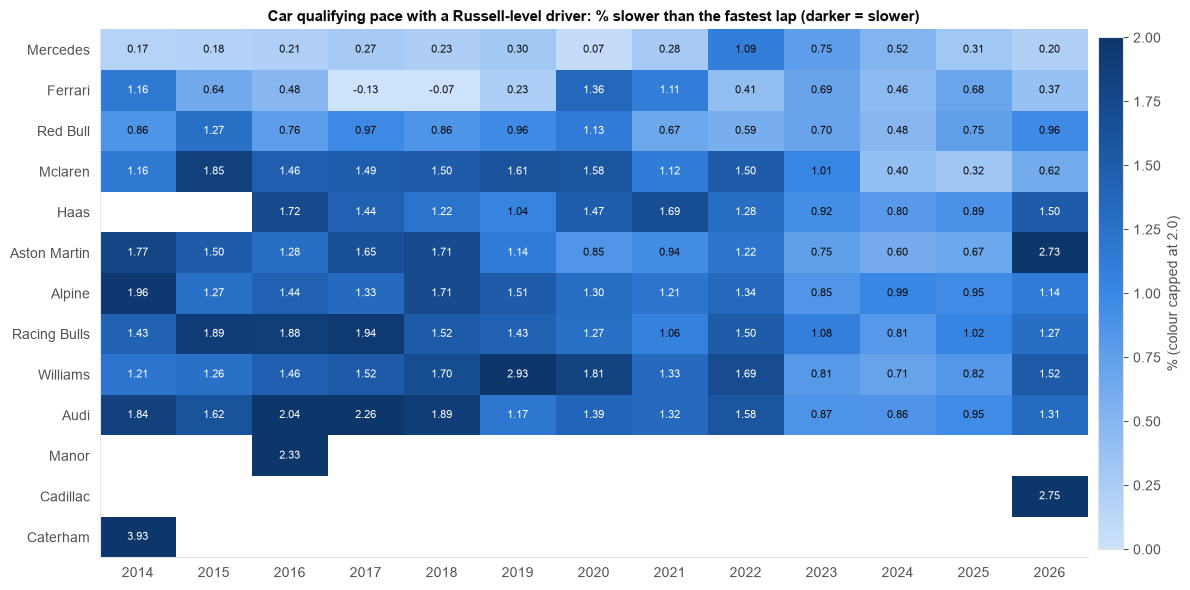

In [10]:
car['lineage'] = car['team'].map(TEAM_LINEAGE).fillna(car['team'])
grid = car.pivot_table(index='lineage', columns='year', values='car_pace')
grid = grid.loc[grid.mean(axis=1).sort_values().index]

cmap = LinearSegmentedColormap.from_list('blue_ramp', BLUE_RAMP)
cmap.set_bad('white')
vmax = 2.0
fig, ax = plt.subplots(figsize=(12, 6))
im = ax.imshow(grid.clip(upper=vmax).to_numpy(), cmap=cmap, vmin=0, vmax=vmax, aspect='auto')
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        v = grid.iat[i, j]
        if pd.notna(v):
            ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=8,
                    color='white' if v > 0.55 * vmax else INK)
ax.set_xticks(range(grid.shape[1]), grid.columns)
ax.set_yticks(range(grid.shape[0]), [t.replace('-', ' ').title() for t in grid.index])
ax.grid(False)
ax.set_title('Car qualifying pace with a Russell-level driver: % slower than the fastest lap (darker = slower)')
cbar = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01)
cbar.set_label(f'% (colour capped at {vmax})')
fig.tight_layout()
fig.savefig('figures/car_pace_heatmap.png', bbox_inches='tight')
plt.show()

In [11]:
ratings.to_csv('data/driver_ratings.csv', index=False)
backtest.to_csv('data/chain_backtest.csv', index=False)
car_pairs.to_csv('data/car_pace_pairs.csv', index=False)
car.drop(columns='lineage').to_csv('data/car_pace.csv', index=False)
print('saved driver_ratings, chain_backtest, car_pace_pairs and car_pace to data/')

saved driver_ratings, chain_backtest, car_pace_pairs and car_pace to data/
